# Extensões (além do estudo pedido no enunciado)

Usa as mesmas funções de `src/` e grava nas mesmas pastas `results/` e `figures/` que o `pipeline.ipynb`,
então as tabelas e figuras finais incluem as extensões. Nada aqui refaz os treinos do estudo principal.

1. **Linha P — pixels crus:** os probes direto nos pixels (32×32×3 = 3072-d), sem encoder. Mostra quanto do
   desempenho de A vem da arquitetura e quanto já está nos pixels.
2. **Alunos extras (stretch goal):** tamanhos M (×1,0, 2,8M) e XL (×1,8, 9,1M) da mesma família, só no experimento
   principal (100% dos dados, 2 seeds, sem ablação), para a curva C − B × parâmetros ter 4 pontos.

**Pré-requisito:** a grade da SVM RBF já corrigida e os probes refeitos no `pipeline.ipynb`
(apague `results/probes/`, `results/clusters/` e `results/probe_hparams.json`, depois rode a célula da seção 9).

In [1]:
import os, sys, json
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

%load_ext autoreload
%autoreload 2
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, display
from src import config as C
from src.common import DEVICE
from src.models import all_sizes, build_student, n_params
from src.extract import extract, all_encoders
from src.probe import select, run, HP_PATH
from src.train import train
from src import cost
from src.report import run as report, load_probes, summarize

assert hasattr(C, "EXTRA_SIZES"), "adicione EXTRA_SIZES / EXTRA_SEEDS ao src/config.py (ver README)"
assert HP_PATH.exists(), "rode antes a seção 9 do pipeline.ipynb (seleção + probes com a grade nova)"
print(json.loads(HP_PATH.read_text()))
print("tamanhos:", all_sizes(), "| seeds extras:", C.EXTRA_SEEDS)

{'selected_on': 'B_S_s0_d100', 'n_cv': 10000, 'linear_C': 0.1, 'linear_cv_acc': 0.8993002479612088, 'rbf_C': 1.0, 'rbf_gamma_mult': 2.0, 'rbf_cv_acc': 0.9090000181781827}
tamanhos: {'S': 0.5, 'L': 1.5, 'M': 1.0, 'XL': 1.8} | seeds extras: {'M': [0, 1], 'XL': [0, 1]}


## 1. Linha P — pixels crus
Mesma transformação determinística das outras linhas (imagem de 128 px → resize → normalização), só que
para 32×32 e sem rede: o vetor de pixels vai direto para L2 + StandardScaler + probes, com os mesmos
subconjuntos rotulados e os mesmos C/γ. Sem treino; alguns minutos de CPU.

In [2]:
extract("P")
display(pd.Series(json.loads((C.RESULTS / "sanity_P.json").read_text())))
run("P")

[extract] P cached


knn_acc             0.258078
chance              0.186351
emb_std             0.010255
emb_std_x_sqrt_d    0.568373
kmeans_nmi          0.467157
kmeans_ari          0.379402
dtype: float64

/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[probe] P: linear acc by frac 0.01:0.228, 0.01:0.234, 0.01:0.225, 0.1:0.366, 0.1:0.371, 0.1:0.369, 0.5:0.460, 0.5:0.452, 0.5:0.463, 1.0:0.479 | NMI 0.479


In [3]:
# probe linear: P contra as linhas do estudo principal (100% dos dados não rotulados)
s = summarize(load_probes())
t = s[(s.probe == "linear") & (s.data_frac == 1.0) & s["size"].isin(["-", "S", "L"])].copy()
t["v"] = (100 * t["mean"]).round(1).astype(str) + " ± " + (100 * t["std"].fillna(0)).round(1).astype(str)
tab = t.pivot_table(index=["row", "size"], columns="label_frac", values="v", aggfunc="first")
tab.columns = [f"{int(c * 100)}%" for c in tab.columns]
display(tab)
cl = pd.DataFrame([json.loads(p.read_text()) for p in (C.RESULTS / "clusters").glob("*.json")])
display(cl[cl.row.isin(["P", "A", "D"])][["tag", "feat_dim", "kmeans_nmi", "kmeans_ari"]]
        .sort_values("tag").round(3))

1%         10%         50%        100%
row size                                                
A   L     42.9 ± 1.5  60.0 ± 1.7  65.0 ± 1.6  65.4 ± 2.1
    S     44.0 ± 2.6  53.2 ± 2.2  55.2 ± 2.4  55.5 ± 2.7
B   L     89.7 ± 0.7  90.1 ± 0.4  91.2 ± 0.1  91.4 ± 0.4
    S     86.2 ± 0.7  88.2 ± 0.3  88.9 ± 0.1  89.1 ± 0.1
C   L     92.5 ± 0.8  93.2 ± 0.3  94.4 ± 0.3  94.7 ± 0.2
    S     89.9 ± 0.4  91.5 ± 0.8  91.8 ± 0.7  91.9 ± 0.7
D   -     91.3 ± 0.9  92.3 ± 0.4  94.1 ± 0.1  94.7 ± 0.0
P   -     22.9 ± 0.5  36.9 ± 0.2  45.8 ± 0.6  47.9 ± 0.0

,tag,feat_dim,kmeans_nmi,kmeans_ari
23,A_L_s0,384,0.502,0.433
1,A_L_s1,384,0.518,0.450
17,A_M_s0,256,0.500,0.363
3,A_M_s1,256,0.441,0.348
10,A_S_s0,128,0.403,0.315
20,A_S_s1,128,0.402,0.308
4,A_S_s2,128,0.446,0.344
25,A_XL_s0,464,0.561,0.473
26,A_XL_s1,464,0.493,0.370
29,D,384,0.870,0.837


## 2. Alunos extras: M e XL
Mesma família (só a largura muda), mesmo orçamento e protocolo do estudo principal (40 épocas, mesmas
views em cache, mesmos probes), 2 seeds cada. Estimativa na RTX 3050: ~4–5 h no total — rode de madrugada.
Tudo é cacheado e retomável: se cair, rode a célula de novo.

In [2]:
rows = []
for z, m in sorted(all_sizes().items(), key=lambda kv: kv[1]):
    net = build_student(z).to(DEVICE)
    rows.append({"size": z, "width_mult": m, "widths": net.widths,
                 "params_M": round(n_params(net) / 1e6, 2),
                 "gflops": round(cost.flops_per_image(net, C.IMG_SIZE) / 1e9, 3),
                 "feat_dim": net.num_features,
                 "extensão": z in C.EXTRA_SIZES})
pd.DataFrame(rows)

,size,width_mult,widths,params_M,gflops,feat_dim,extensão
0,S,0.5,"[16, 32, 64, 128]",0.70,0.070,128,False
1,M,1.0,"[32, 64, 128, 256]",2.80,0.279,256,True
2,L,1.5,"[48, 96, 192, 384]",6.28,0.626,384,False
3,XL,1.8,"[56, 112, 232, 464]",9.13,0.880,464,True


In [3]:
for size, seeds in C.EXTRA_SEEDS.items():
    for s in seeds:
        for row in ("B", "C"):
            train(row, size, s)
            torch.cuda.empty_cache()

{
 "name": "B_M_s0_d100",
 "row": "B",
 "size": "M",
 "seed": 0,
 "data_frac": 1.0,
 "n_unlabeled": 89996,
 "k_views": 8,
 "epochs": 40,
 "batch": 256,
 "lr": 0.001,
 "wd": 0.05,
 "steps_per_epoch": 351,
 "total_steps": 14040,
 "img_size": 64,
 "params_backbone": 2795040,
 "params_head": 8927232,
 "feat_dim": 256,
 "device": "cuda",
 "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU"
}
[B_M_s0_d100] ep 1/40 step 350/351 loss 21.3922
[B_M_s0_d100] ep 2/40 step 350/351 loss 20.6816
[B_M_s0_d100] ep 3/40 step 350/351 loss 20.1450
[B_M_s0_d100] ep 4/40 step 350/351 loss 19.6800
[B_M_s0_d100] ep 5/40 step 350/351 loss 19.3423
[B_M_s0_d100] ep 6/40 step 350/351 loss 19.1152
[B_M_s0_d100] ep 7/40 step 350/351 loss 18.7097
[B_M_s0_d100] ep 8/40 step 350/351 loss 18.7978
[B_M_s0_d100] ep 9/40 step 350/351 loss 18.7395
[B_M_s0_d100] ep 10/40 step 350/351 loss 18.4638
[B_M_s0_d100] collapse check: {'knn_acc': 0.845, 'chance': 0.136, 'emb_std': 0.04490632936358452, 'emb_std_x_sqrt_d': 0.7185012698173523,

In [4]:
# features (A das seeds extras + os novos B/C), probes, custo
for j in all_encoders():
    extract(*j)
for p in sorted(C.FEATS.glob("*.npz")):
    run(p.stem)
cost.main()

[extract] D cached
[extract] A_S_s0 cached
[extract] A_S_s1 cached
[extract] A_S_s2 cached
[extract] A_L_s0 cached
[extract] A_L_s1 cached
[extract] A_M_s0 cached
[extract] A_M_s1 cached
[extract] A_XL_s0 cached
[extract] A_XL_s1 cached
[extract] P cached
[extract] B_L_s0_d100 cached
[extract] B_L_s0_d50 cached
[extract] B_L_s1_d100 cached
[extract] B_L_s1_d50 cached


/home/kdunorat/Projetos/distillation-unsupervised/src/extract.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(C.RUNS / C.tag(row, size, seed, data_frac)

[extract] B_M_s0_d100: train (89996, 256) test (7180, 256) -> B_M_s0_d100.npz
[extract] B_M_s1_d100: train (89996, 256) test (7180, 256) -> B_M_s1_d100.npz
[extract] B_S_s0_d100 cached
[extract] B_S_s0_d50 cached
[extract] B_S_s1_d100 cached
[extract] B_S_s1_d50 cached
[extract] B_S_s2_d100 cached
[extract] B_S_s2_d50 cached
[extract] B_XL_s0_d100: train (89996, 464) test (7180, 464) -> B_XL_s0_d100.npz
[extract] B_XL_s1_d100: train (89996, 464) test (7180, 464) -> B_XL_s1_d100.npz
[extract] C_L_s0_d100 cached
[extract] C_L_s0_d50 cached
[extract] C_L_s1_d100 cached
[extract] C_L_s1_d50 cached
[extract] C_M_s0_d100: train (89996, 256) test (7180, 256) -> C_M_s0_d100.npz
[extract] C_M_s1_d100: train (89996, 256) test (7180, 256) -> C_M_s1_d100.npz
[extract] C_S_s0_d100 cached
[extract] C_S_s0_d50 cached
[extract] C_S_s1_d100 cached
[extract] C_S_s1_d50 cached
[extract] C_S_s2_d100 cached
[extract] C_S_s2_d50 cached
[extract] C_XL_s0_d100: train (89996, 464) test (7180, 464) -> C_XL_s0_d

   encoder  input_size  params_M  gflops_per_image  feat_dim  latency_ms_batch128  throughput_img_s                             device            amp
 student_S          64  0.700176          0.070091       128             2.921853      43807.820077 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
 student_L          64  6.284592          0.625508       384            11.366824      11260.841278 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
 student_M          64  2.795040          0.278594       256             5.518968      23192.743008 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
student_XL          64  9.127016          0.879567       464            16.912128       7568.532915 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
   teacher         224 21.665664          9.196997       384           141.725875        903.151949 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
                 name       row size  seed  data_frac  epochs  total_steps  train_gpu_hours
        

## 3. Relatório atualizado (inclui P e os 4 tamanhos)


### linear probe accuracy (%), mean ± std over seeds × draws

| row   | size   | 1%         | 10%        | 50%        | 100%       |
|:------|:-------|:-----------|:-----------|:-----------|:-----------|
| A     | L      | 42.9 ± 1.5 | 60.0 ± 1.7 | 65.0 ± 1.6 | 65.4 ± 2.1 |
| A     | M      | 41.1 ± 2.3 | 56.0 ± 0.5 | 60.1 ± 0.6 | 60.6 ± 0.5 |
| A     | S      | 44.0 ± 2.6 | 53.2 ± 2.2 | 55.2 ± 2.4 | 55.5 ± 2.7 |
| A     | XL     | 42.8 ± 1.0 | 58.9 ± 1.5 | 64.3 ± 1.3 | 64.6 ± 1.0 |
| B     | L      | 89.7 ± 0.7 | 90.1 ± 0.4 | 91.2 ± 0.1 | 91.4 ± 0.4 |
| B     | M      | 88.1 ± 0.3 | 89.6 ± 0.3 | 90.7 ± 0.2 | 90.9 ± 0.3 |
| B     | S      | 86.2 ± 0.7 | 88.2 ± 0.3 | 88.9 ± 0.1 | 89.1 ± 0.1 |
| B     | XL     | 89.5 ± 0.5 | 90.7 ± 0.4 | 91.3 ± 0.1 | 91.4 ± 0.1 |
| C     | L      | 92.5 ± 0.8 | 93.2 ± 0.3 | 94.4 ± 0.3 | 94.7 ± 0.2 |
| C     | M      | 91.0 ± 0.8 | 92.8 ± 0.2 | 93.5 ± 0.2 | 93.5 ± 0.0 |
| C     | S      | 89.9 ± 0.4 | 91.5 ± 0.8 | 91.8 ± 0.7 | 91.9 ± 0.7 |
| C     | XL  

I0000 00:00:1795610200.677341  102686 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795610200.713354  102686 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795610202.169649  102686 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 b

[report] figures in /home/kdunorat/Projetos/distillation-unsupervised/figures
C − B (pp), probe linear, 100% dos dados não rotulados


,1%,10%,50%,100%
size,,,,
S,3.71 ± 0.79,3.27 ± 0.57,2.91 ± 0.68,2.82 ± 0.73
M,2.87 ± 0.66,3.24 ± 0.49,2.76 ± 0.12,2.6 ± 0.3
L,2.8 ± 1.28,3.04 ± 0.55,3.23 ± 0.28,3.36 ± 0.25
XL,2.5 ± 1.13,2.57 ± 0.77,2.92 ± 0.2,3.15 ± 0.03


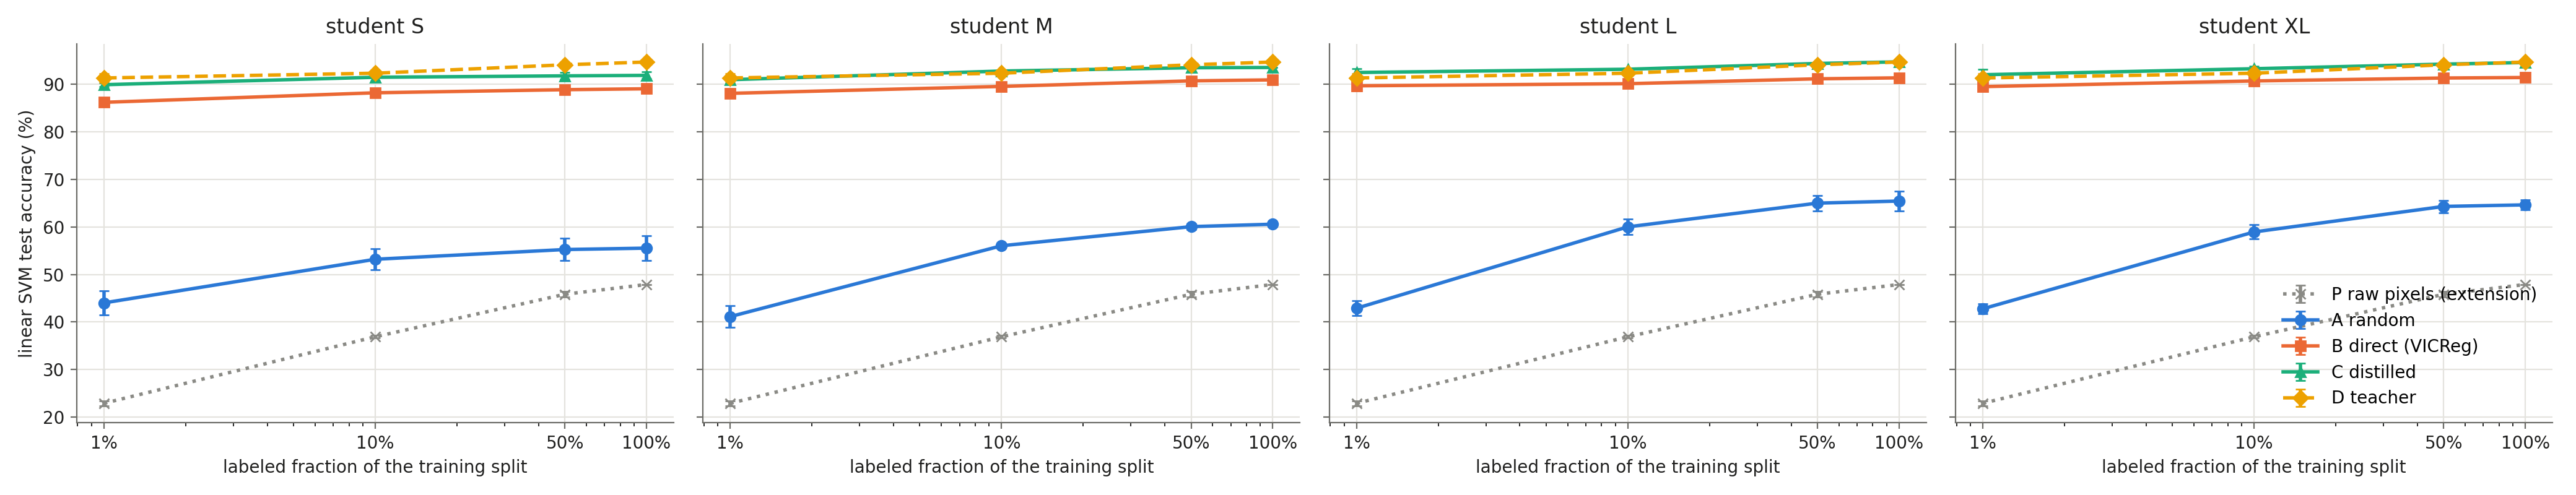

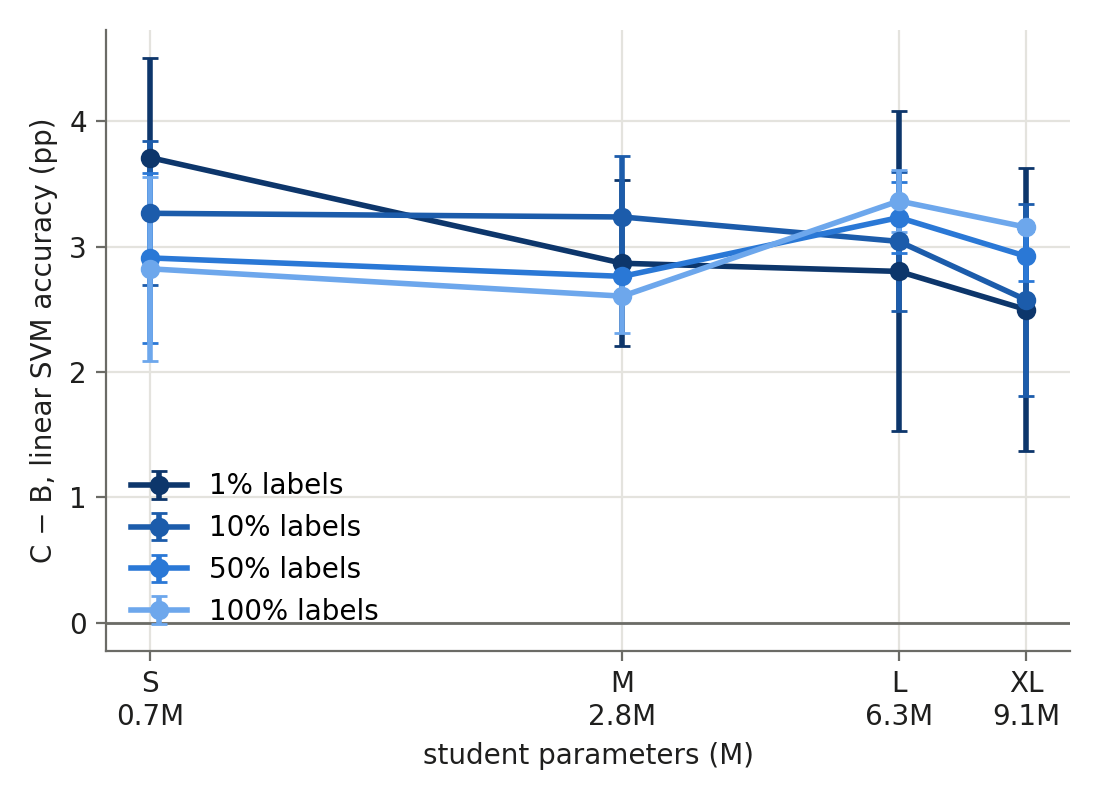

In [2]:
report("umap", "S")
g = pd.read_csv(C.RESULTS / "gap.csv")
g = g[(g.probe == "linear") & (g.data_frac == 1.0)].copy()
order = sorted(all_sizes(), key=all_sizes().get)
g["size"] = pd.Categorical(g["size"], order, ordered=True)
g["v"] = (100 * g["mean"]).round(2).astype(str) + " ± " + (100 * g["std"].fillna(0)).round(2).astype(str)
gt = g.pivot_table(index="size", columns="label_frac", values="v", aggfunc="first", observed=True)
gt.columns = [f"{int(c * 100)}%" for c in gt.columns]
print("C − B (pp), probe linear, 100% dos dados não rotulados")
display(gt)
for f in ["label_efficiency", "gap_vs_params"]:
    display(Image(str(C.FIGS / f"{f}.png")))